In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy import stats
import scanpy as sc
import anndata as ad

In [2]:
import scHPT

In [3]:
from scipy.stats import linregress
import matplotlib.colors as mplc
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.offsetbox import (DrawingArea, OffsetImage,AnnotationBbox)

# 6-TG, HPRT1 KD data

In [4]:
adata=sc.read('data/sciPlexGxE_1_HPRT1_processed.h5ad')

In [5]:
gene_id = adata.var[adata.var.gene_short_name=='HPRT1'].index
adata.obs['HPRT1_expr'] = adata[:,gene_id].X.A.reshape(-1)

In [6]:
adata.obs.head(5)

,gRNA_library,dose,treatment,gene_id,proliferation_index,HPRT1_expr
10B_G10_RT_BC_24_Lig_BC_39,HPRT1,0.0,dmso,HPRT1,2.590628,0.053861
06B_F06_RT_BC_21_Lig_BC_42,HPRT1,0.0,dmso,HPRT1,2.608393,0.149152
01B_D01_RT_BC_16_Lig_BC_10,HPRT1,0.0,dmso,HPRT1,4.041131,0.115461
05B_A05_RT_BC_39_Lig_BC_40,HPRT1,0.0,dmso,HPRT1,3.167752,0.103661
09B_G09_RT_BC_2_Lig_BC_48,HPRT1,0.0,dmso,HPRT1,3.083498,0.455105


# Test 1

In [12]:
# Y = proliferation index, calculated in sci-plex-G*E papar,
# T = 6-TG v.s, dmso (control)
res=scHPT.permute_test(adata=adata, Y_column='proliferation_index', T_column='treatment',
                       pert_name='thioguanine', ctrl_name='dmso',n_perm=1000, verbose=True)

In [13]:
pval_final_all=res[0]
tau_hat_all=res[4]
tau_sd_all=res[5]

In [14]:
pval_final_all # test1 pvalue

0.014000000000000012

In [15]:
tau_hat_all,tau_sd_all # estimation of tau and sd(tau)

(-0.4465266318376684, 0.12040289811405304)

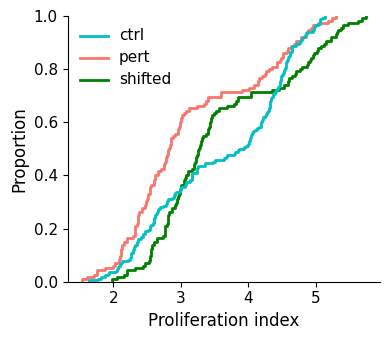

In [16]:
# draw shifted cdf plot
data_df=(pd.DataFrame([list(adata.obs.proliferation_index),
                       list(adata.obs.treatment)])).T
data_df.columns=['Yobs','pert']
pert_dict={'thioguanine':1,'dmso':0}
data_df["pert"].replace(pert_dict, inplace=True)
shifted_df=data_df[data_df.pert==1].copy()
data0_obs=(data_df[data_df.pert==0])['Yobs'].values
data1_obs=(data_df[data_df.pert==1])['Yobs'].values
tau_hat=np.mean(data1_obs)-np.mean(data0_obs)
shifted_df['Yobs']=shifted_df['Yobs']-tau_hat
shifted_df['pert']=2
data_df_drawcdf=pd.concat([data_df, shifted_df], ignore_index=True, sort=False)
rename_dict = {0: 'ctrl', 1: 'pert', 2: 'shifted'}
data_df_drawcdf['pert'] = data_df_drawcdf['pert'].replace(rename_dict)

# set color
palette = {
    'ctrl': '#02BFC5',
    'pert': '#F8776C',
    'shifted': 'g'
}

# set fig
plt.figure(figsize=(4, 3.5))
ax = sns.ecdfplot(data=data_df_drawcdf, x="Yobs", hue="pert", palette=palette, linewidth=2)

sns.despine()
legend = ax.legend_
if legend:
    legend.set_frame_on(False)
    legend.set_title(None) 
    for text in legend.get_texts():
        text.set_fontsize(11)  

plt.xlabel('Proliferation index', fontsize=12)
plt.ylabel('Proportion',fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
# plt.savefig('all_figs/nutlin+hprt1/hprt1.svg', format='svg')  # save fig
plt.show()

# Test 2

In [19]:
# Y = proliferation index, calculated in sci-plex-G*E papar,
# T = 6-TG v.s, dmso (control)
# C = HPRT1-KO cells, HPRT1-control cells
final_res_df=scHPT.permute_test_group(adata=adata, Y_column='proliferation_index', T_column='treatment',
                                      group_column='gene_id', pert_name='thioguanine', ctrl_name='dmso',
                                      n_cell_min=30,n_perm=1000)

Finish permutation : 0
Finish permutation : 100
Finish permutation : 200
Finish permutation : 300
Finish permutation : 400
Finish permutation : 500
Finish permutation : 600
Finish permutation : 700
Finish permutation : 800
Finish permutation : 900


In [20]:
final_res_df

,group,p_val,tau_hat,tau_sd,tau_star,sks_obs
0,NTC,0.011,-0.997431,0.15495,-1.238947,0.263946
1,HPRT1,0.652,0.034065,0.169826,0.004654,0.1


In [21]:
err_list=[]
for i in range(len(final_res_df)):
    err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_err']=err_list

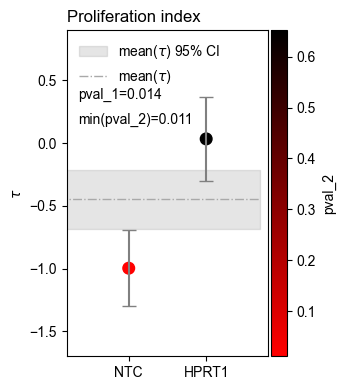

In [24]:
with plt.rc_context({'figure.figsize': (3.5, 4),'font.sans-serif':['Arial']}):
   
    rbcmap = mplc.LinearSegmentedColormap.from_list("", ["red","black"])
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.errorbar(final_res_df['group'], final_res_df['tau_hat'], yerr = final_res_df['95_err'], ls = "None", capsize=5,color = "grey")
    #im=ax.scatter(final_res_df['group'], final_res_df['tau_hat'],  marker = "o", c = -np.log10(final_res_df['p_val'].values.astype(np.float64)),cmap=rbcmap)
    im=ax.scatter(final_res_df['group'], final_res_df['tau_hat'],  marker = "o", c = final_res_df['p_val'],s=70,cmap=rbcmap)
    ax.set_ylabel(r'$\tau$')
    cbar=plt.colorbar(im,ax=ax,pad=0.01)
    #cbar.set_label('-log10(p-val)', rotation=90)
    cbar.set_label('pval_2', rotation=90)
    plt.xlim([-0.8,1.8])
    plt.ylim([-1.7,0.9])

    all_CI_min,all_CI_max=stats.norm.interval(1-0.05, loc=tau_hat_all, scale=tau_sd_all)
    ax.fill_between([-1.6,1.7],all_CI_min,all_CI_max,alpha=0.2, color='grey', label = r'mean($\tau$) 95% CI')
    ax.hlines(y=tau_hat_all, xmin=-1.7, xmax=1.7, linewidth=1, color='darkgrey',linestyle='-.',label=r'mean($\tau$)')
    plt.legend(frameon=False,loc='upper left')
    
    ax.text(-0.65,0.35,'pval_1={}'.format(round(pval_final_all,3)))
    ax.text(-0.65,0.15,'min(pval_2)={}'.format(round(final_res_df.p_val.min(),3)))
    plt.title('Proliferation index',loc='left')
    plt.tight_layout()
    #plt.savefig('all_figs/nutlin+hprt1/hprt2.svg', format='svg') # save fig
    plt.show()

The heterogeneous effects still exist in HPRT1-control cells.

# Test 3

In [7]:
# Y = proliferation index, calculated in sci-plex-G*E papar,
# T = 6-TG v.s, dmso (control)
# Z = HPRT1 expression
res_cov = scHPT.permute_test_cov(adata=adata, Y_column='proliferation_index', T_column='treatment',
                                 covs_columns=['HPRT1_expr'], pert_name='thioguanine', ctrl_name='dmso',n_perm=1000)

In [8]:
pval_final = res_cov[0]
beta_hat = res_cov[4]

In [9]:
pval_final # test 3 pvalue

0.21499999999999997

In [10]:
beta_hat # estimation of beta_0 (intercept) and beta_1 (HPRT1_expr)

array([[-0.14479922],
       [-1.87479559]])

In [11]:
### plot perturbation effects in HPRT1 experssion bins
data_df=(pd.DataFrame([list(adata.obs.proliferation_index),
                       list(adata.obs.treatment),
                      list(adata.obs.HPRT1_expr)])).T
data_df.columns=['Yobs','pert','HPRT1']
pert_dict={'thioguanine':1,'dmso':0}
data_df["pert"].replace(pert_dict, inplace=True)
num_g=7
data_df['x_group'] = pd.qcut(data_df['HPRT1'], q=num_g, labels=False)
data_df['bin'] = pd.qcut(data_df['HPRT1'], q=num_g)
dfs = [data_df[data_df['x_group'] == i] for i in range(num_g)]
x_mean=[]
tau_hat=[]
tau_sd=[]
for df in dfs:
    data0_obs=(df[df.pert==0])['Yobs'].values
    data1_obs=(df[df.pert==1])['Yobs'].values
    n0 = len(data0_obs)
    n1 = len(data1_obs)
    x_mean.append(np.mean(df.HPRT1.values))
    tau_hat.append(np.mean(data1_obs)-np.mean(data0_obs))
    tau_sd.append(np.sqrt(np.var(data1_obs, ddof=1) / n1 + np.var(data0_obs, ddof=1) / n0))

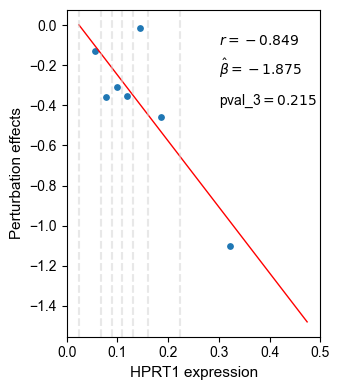

In [14]:
# calculate mean difference in each bin
grouped = data_df.groupby('bin').agg(
    y_mean=('pert', 'mean')
).reset_index()

# get bin loc
grouped['bin_interval'] = grouped['bin'].astype(object)
grouped['x_left'] = grouped['bin_interval'].apply(lambda x: float(x.left))
grouped['x_right'] = grouped['bin_interval'].apply(lambda x: float(x.right))

with plt.rc_context({'figure.figsize': (3.5, 4),'font.sans-serif':['Arial']}):
    plt.scatter(x_mean, tau_hat,s=15)
    slope, intercept, r_value, p_value, std_err = linregress(x_mean, tau_hat)
    x_range=np.arange(grouped['x_left'].values[0],0.5,0.05)
    regression_line_y = slope * x_range + intercept
    plt.plot(x_range, regression_line_y, color='red', linewidth=1,label=f'r={r_value:.2f}')

    vlines=list(grouped['x_left'].values)
    for x_pos in vlines:
        plt.axvline(x=x_pos, color='lightgray', linestyle='--',alpha=0.5)

    plt.xlim([0,0.5])
    plt.xlabel('HPRT1 expression',fontsize=11)
    plt.ylabel('Perturbation effects',fontsize=11)
    plt.text(0.3,-0.1,f'$r={r_value:.3f}$',fontsize=10)
    plt.text(0.3,-0.25,r'$\hat{\beta}$'+f'$={beta_hat[1][0]:.3f}$',fontsize=10)
    plt.text(0.3,-0.4,f'pval_3$={pval_final:.3f}$',fontsize=10)
    plt.tight_layout()
    # plt.savefig('all_figs/nutlin+hprt1/hprt3.svg', format='svg') # save fig
    plt.show()

The heterogeneous effects can be explained by HPRT1 expression.